# Classifying Look-Alike Garments
### A Comparative Study of Binary, Multiclass and Multilabel Learning on Fashion-MNIST

This notebook walks through the whole project. The reusable code lives in the `garments` package (`src/garments/`); each section below
calls it, shows the results and answers the guiding questions for that step. The same code is run end to end, without the commentary,
by `scripts/run_experiments.py`.

**Structure:** 1 Data, 2-3 Binary task (labels, first classifier), 4-6 Evaluating the binary classifier, 7 Preprocessing,
8-10 Thresholds, precision-recall and ROC, 11-12 Multiclass, 13 Multilabel, 14 Final test-set evaluation, 15 Conclusions.

**Protocol:** every choice is made with 3-fold stratified cross-validation on the 60,000 training images; the 10,000 test images are used once, in section 14.

**Run time:** about 20-30 minutes in total on a laptop (sections 4, 12 and 14 are the slow ones). The written answers quote the numbers of the full run;
with `GARMENTS_QUICK=1` (a tiny subsample for a smoke test) the code runs but the numbers differ.

In [1]:
import os
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import pandas as pd
from IPython.display import Image, display

from garments import config as C
from garments import experiments as E
from garments.data import binary_target, load_data

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

QUICK = os.environ.get("GARMENTS_QUICK") == "1"
data = load_data(quick=QUICK)
print("Data source:", data.source, "| train", data.X_train.shape, "| test", data.X_test.shape)

def show(name, width=700):
    display(Image(filename=str(C.FIG_DIR / name), width=width))

Data source: Kaggle CSV | train (60000, 784) | test (10000, 784)


## 1. The data

,label,class,train,test,train_%
0,0,T-shirt/top,6000,1000,10.0
1,1,Trouser,6000,1000,10.0
2,2,Pullover,6000,1000,10.0
3,3,Dress,6000,1000,10.0
4,4,Coat,6000,1000,10.0
5,5,Sandal,6000,1000,10.0
6,6,Shirt,6000,1000,10.0
7,7,Sneaker,6000,1000,10.0
8,8,Bag,6000,1000,10.0
9,9,Ankle boot,6000,1000,10.0


,value
data source,Kaggle CSV
images (train + test),70000
train images,60000
test images,10000
features per image,784
classes,10
pixel range,0-255
mean pixel intensity,73.0
std of pixel values,90.0
pixels equal to 0,50.2%


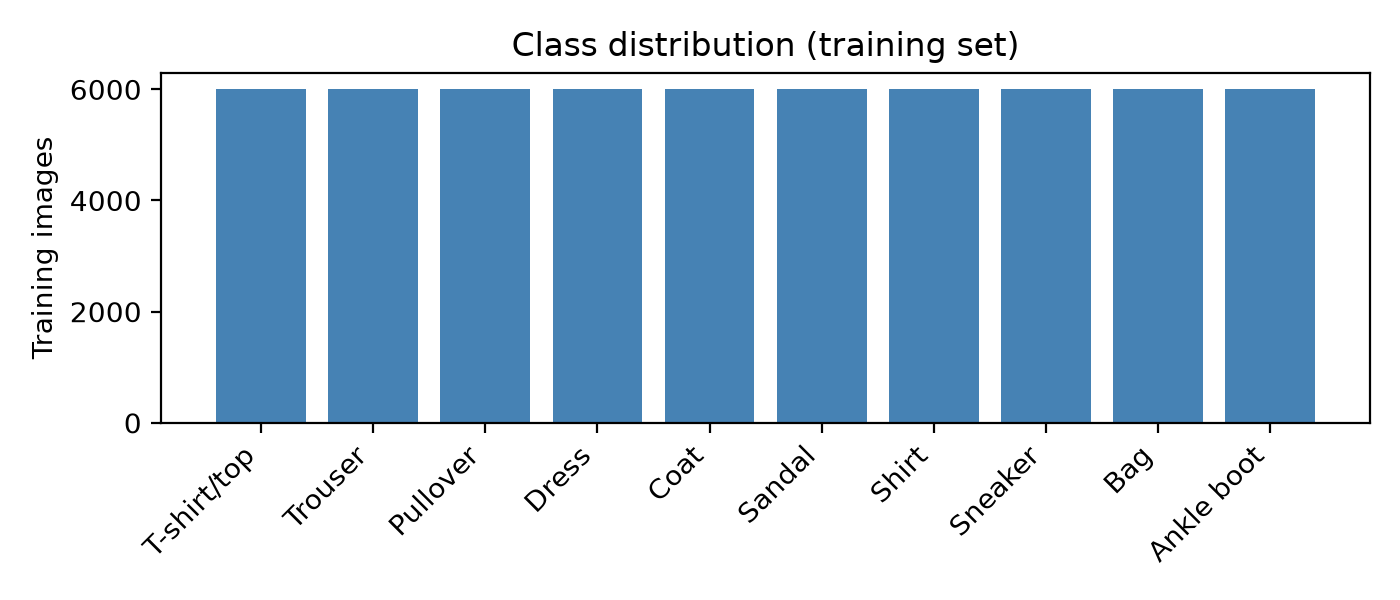

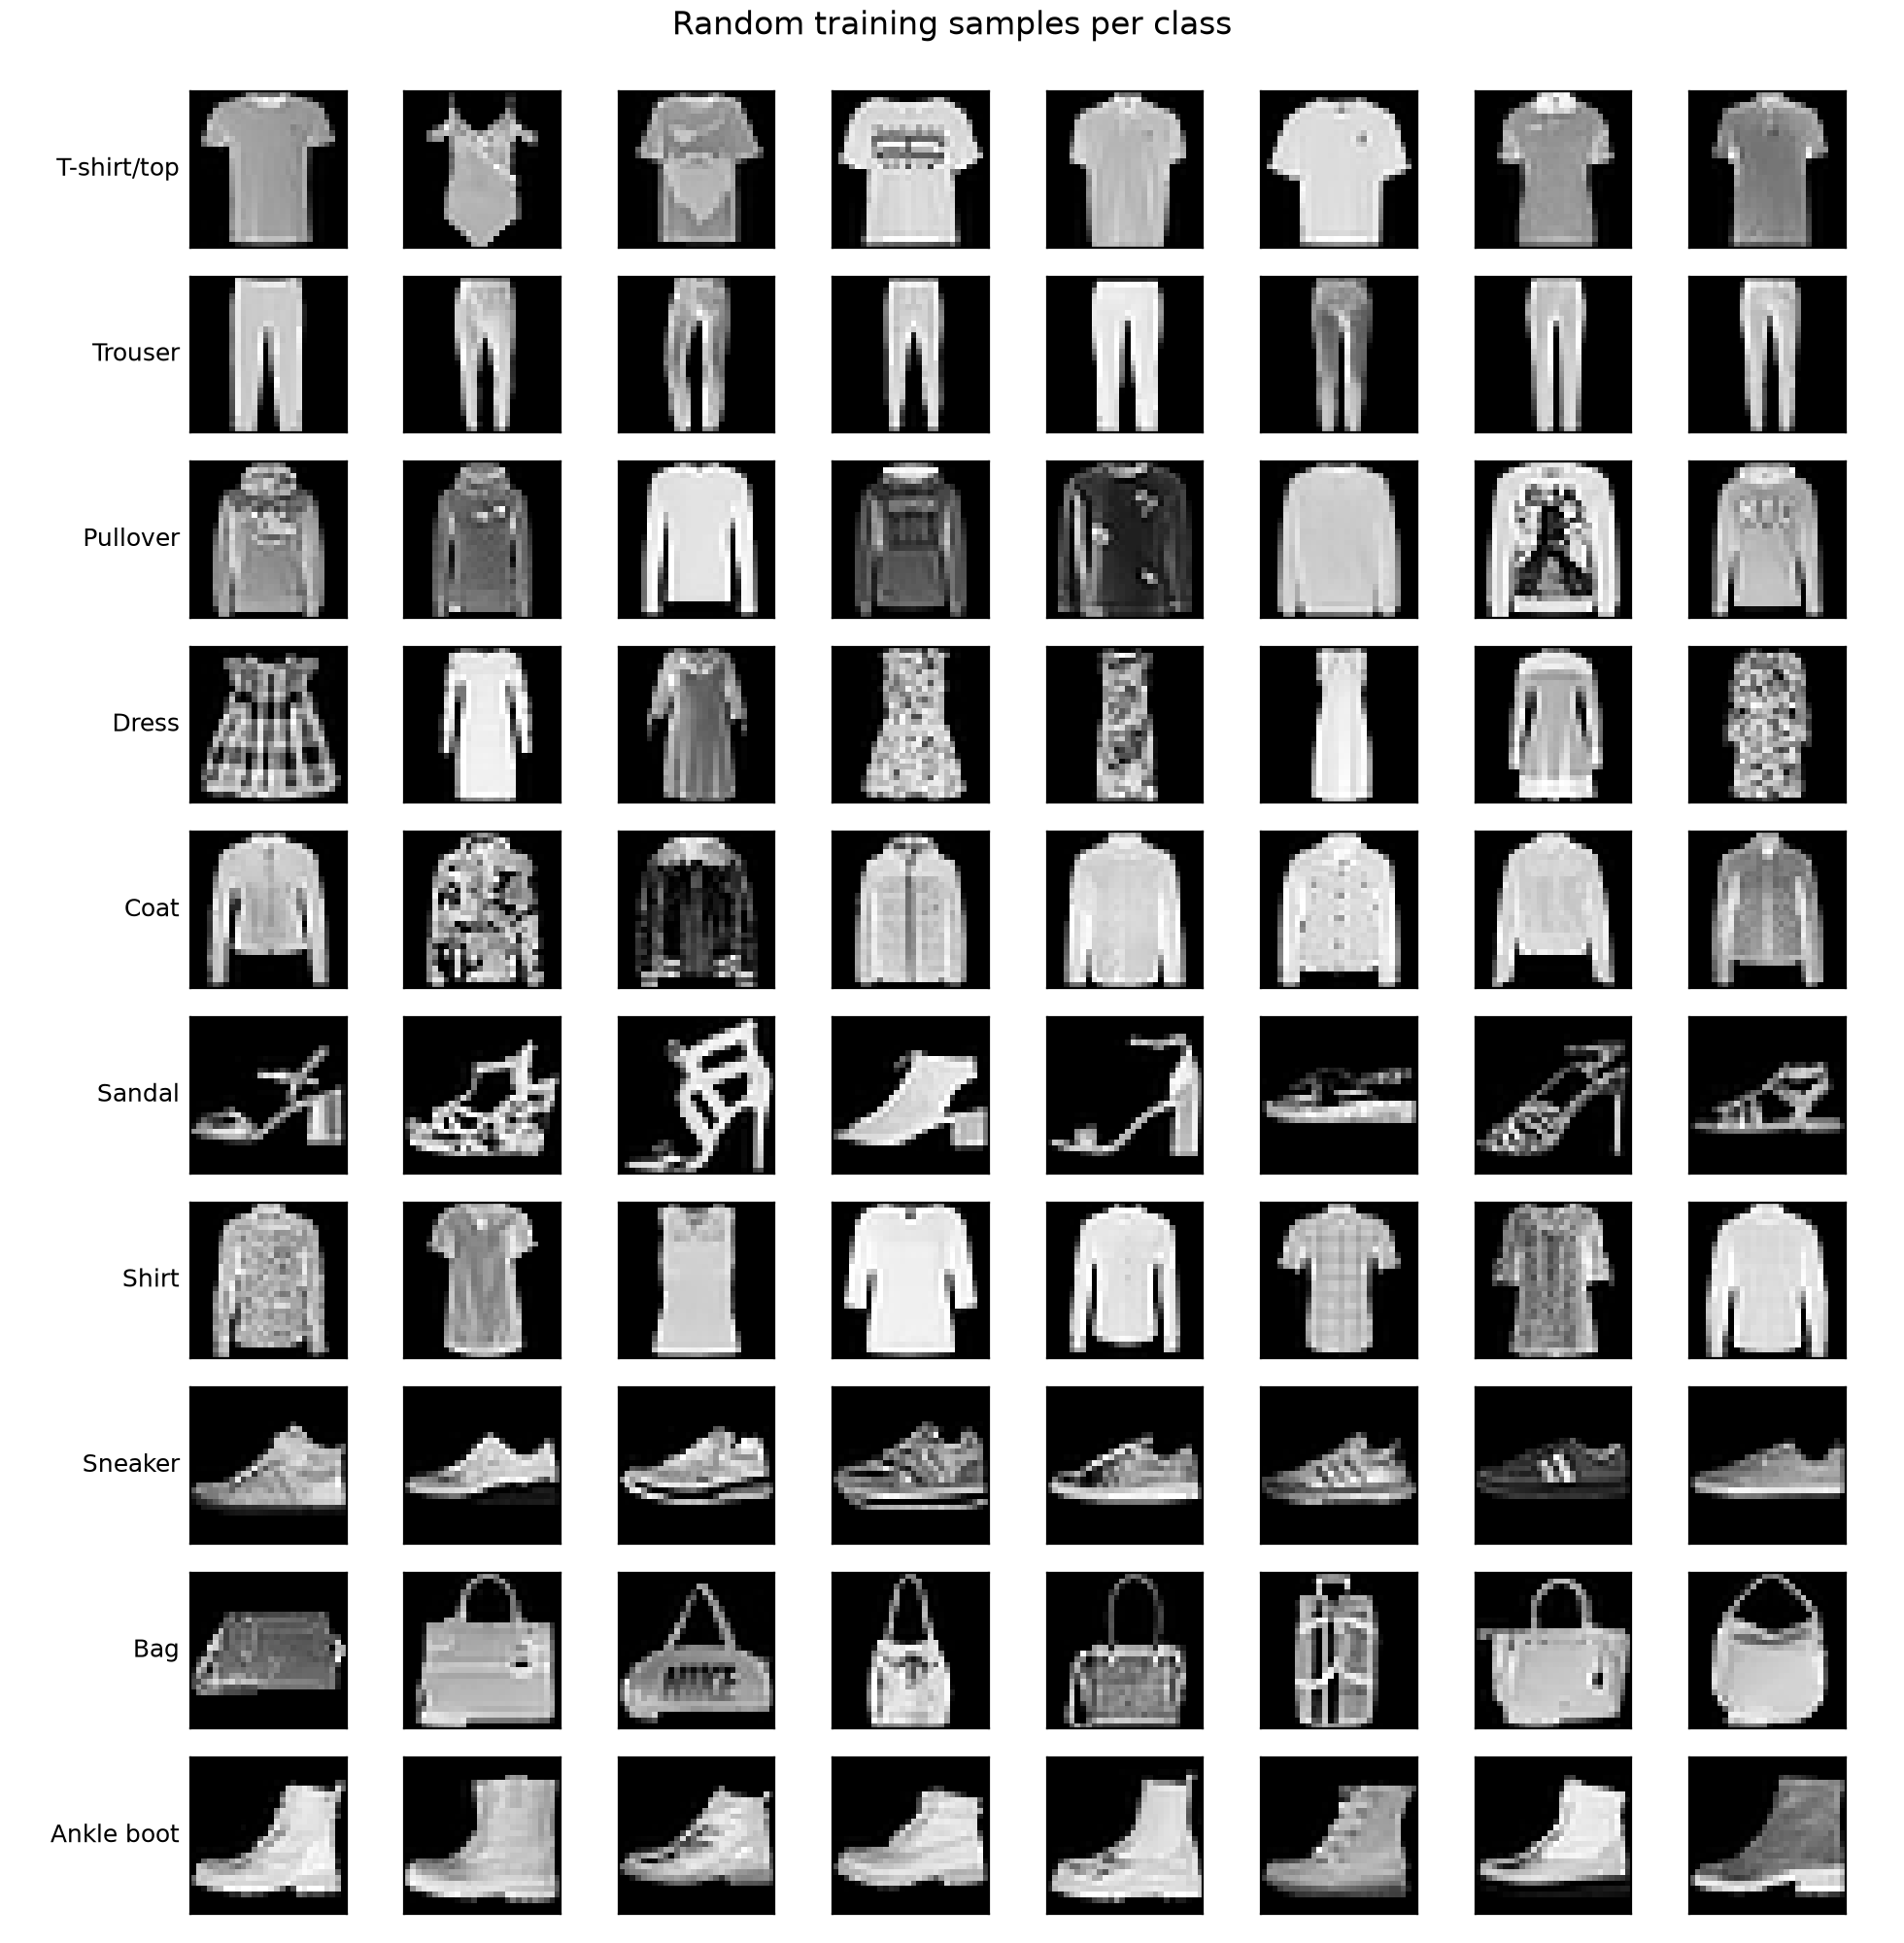

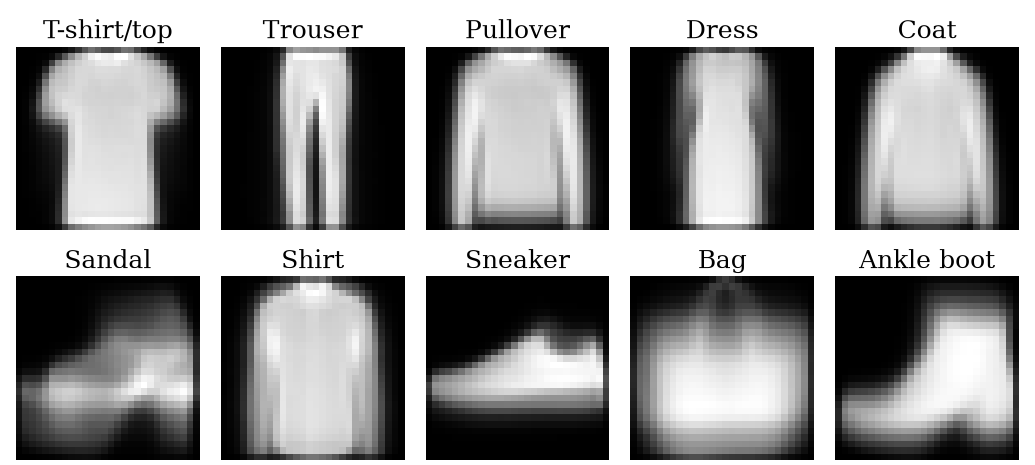

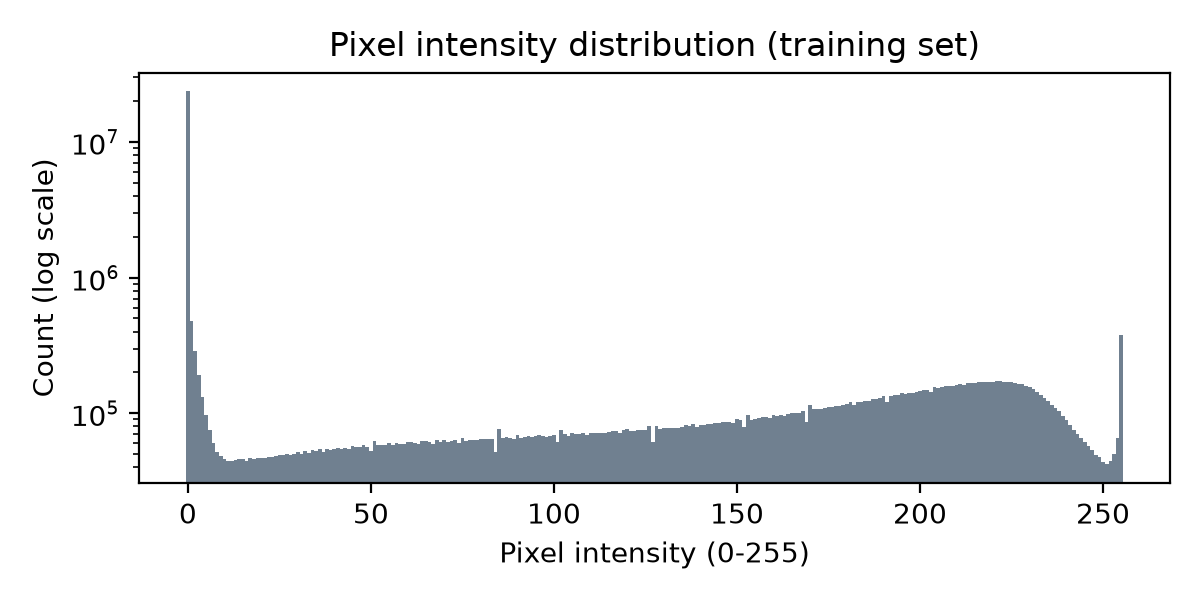

In [2]:
eda = E.eda(data)
display(eda["class_counts"])
display(pd.Series(eda["stats"], name="value").to_frame())
show("eda_class_distribution.png", 600)
show("eda_sample_grid.png", 550)
show("fig_mean_images.png", 520)
show("eda_pixel_histogram.png", 520)

**Q1.1 Guiding questions**

1. **How many images?** 70,000 in total: 60,000 for training and 10,000 for testing.
2. **How many features per image?** 784 (28 x 28 pixels, flattened row by row).
3. **How many classes?** Ten: T-shirt/top, Trouser, Pullover, Dress, Coat, Sandal, Shirt, Sneaker, Bag and Ankle boot.
4. **What does each feature represent?** The grayscale intensity (0 = black background, 255 = brightest) of one pixel at a fixed position.
5. **What is the target variable?** The clothing category (label 0-9).
6. **Why inspect the images before training?** It confirms that the reshape and the label mapping are right, reveals image quality and label noise,
   and shows which classes look alike, which anticipates where a classifier will fail.

**What we observed.** The classes are perfectly balanced (6,000 training and 1,000 test images each). Half of all pixels (50.2%) are exactly 0, the mean intensity
is 73 and the standard deviation 90. The mean images show that Pullover, Coat and Shirt share almost the same long-sleeved silhouette, T-shirt/top differs mainly by shorter sleeves,
and the three footwear classes resemble one another. Classes are also heterogeneous (hoodies among the pullovers, strappy tops among the T-shirts). There are 43 duplicate
images within the training set and 10 test images that also occur in training (0.1%), which we judged negligible.

## 2. The binary task: Shirt versus the rest

In [3]:
y_train_bin = binary_target(data.y_train)
print(f"Positive class: {C.CLASS_NAMES[C.POSITIVE_CLASS]} (label {C.POSITIVE_CLASS}); "
      f"positives in train: {y_train_bin.sum():,} of {len(y_train_bin):,} ({y_train_bin.mean():.1%})")

Positive class: Shirt (label 6); positives in train: 6,000 of 60,000 (10.0%)


**Q2.1 Guiding questions**

1. **What is the positive class?** Shirt (label 6): "is this image a shirt?" is answered with True.
2. **What is the negative class?** Every other garment (the nine remaining classes).
3. **Why is this binary classification?** There are exactly two possible answers, shirt or not shirt.

We chose Shirt because it is the class most easily confused with others (T-shirt/top, Pullover, Coat), which makes the precision/recall trade-off meaningful.
Shirts are 10% of the data, so a classifier that always answers "not shirt" already scores 0.90 accuracy.

## 3. A first binary classifier

A linear classifier trained by stochastic gradient descent (SGD) on the raw pixel values. Ten hand-picked training images: 5 shirts, 4 look-alikes and 1 trouser.

,index,true class,is shirt,predicted shirt,correct
0,46045,Shirt,True,True,True
1,25948,Shirt,True,True,True
2,38663,Shirt,True,True,True
3,5228,Shirt,True,True,True
4,25632,Shirt,True,True,True
5,5414,T-shirt/top,False,False,True
6,31611,Pullover,False,False,True
7,58474,Coat,False,False,True
8,44080,Dress,False,False,True
9,45844,Trouser,False,False,True


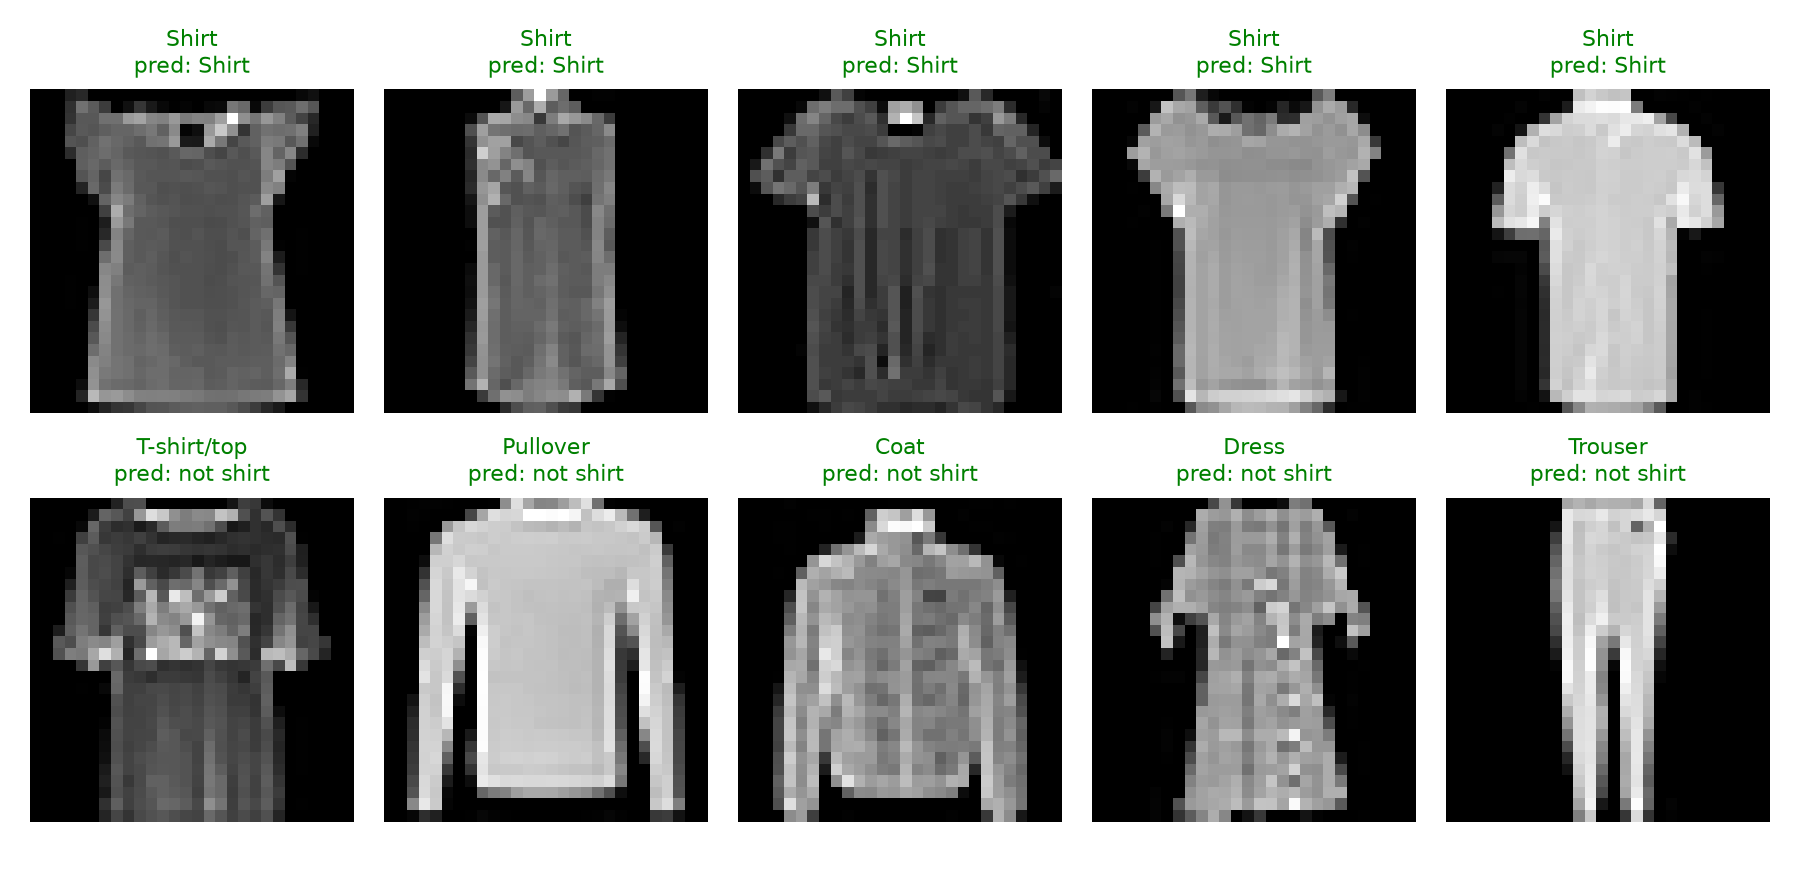

In [4]:
demo = E.binary_demo(data)
display(demo)
show("binary_demo_predictions.png", 700)

**Q3.1 Guiding questions**

1. **Does the classifier identify all shirts?** In this sample, yes: all 5 shirts were recognised.
2. **Does it ever call a non-shirt a shirt?** Not in this sample: the four look-alikes and the trouser were rejected.
3. **Why is checking a few predictions not enough?** The sample is tiny, hand-picked and taken from images the model was trained on, so it says nothing about how often each type of error
   occurs on new images. The cross-validated evaluation below shows 4,430 false positives and 3,296 missed shirts for this very model.

## 4. Accuracy and cross-validation
Three preprocessing variants of the SGD classifier (raw pixels, pixels divided by 255, per-pixel standardisation) are cross-validated with the same folds,
and compared with a dummy classifier that always answers "not shirt". This cell is the slowest of the binary task, because it also contains the convergence re-fits.

In [5]:
bcv = E.binary_cv(data)
cols = ["accuracy", "fold accuracies", "precision", "recall", "f1", "ROC-AUC", "average precision"]
display(bcv["cv_table"][cols])

,accuracy,fold accuracies,precision,recall,f1,ROC-AUC,average precision
"SGD, raw pixels",0.871233,0.9191 / 0.9028 / 0.7919,0.37903,0.450667,0.411756,0.799627,0.376636
SGD + StandardScaler,0.904583,0.9039 / 0.9054 / 0.9044,0.525706,0.468667,0.49555,0.884941,0.438641
SGD + /255,0.924467,0.9255 / 0.9204 / 0.9274,0.702204,0.424833,0.529387,0.904989,0.607235
Dummy (always 'not shirt'),0.9,-,0.0,0.0,0.0,0.5,0.1


**Q4.1 Guiding questions**

1. **What accuracy did we obtain?** Mean cross-validated accuracy of the lab-style raw-pixel model: 0.871 (folds 0.919, 0.903 and 0.792). With pixels divided by 255 it is 0.925.
2. **Is it high?** Not compared with the baseline: always answering "not shirt" scores 0.900. The raw-pixel model is *below* that baseline.
3. **Does high accuracy mean a useful classifier?** No. A classifier can be accurate and still find no shirts at all, as the dummy shows.
4. **What happens if the positive class is rare?** Accuracy is dominated by the common negative class, so a classifier that ignores the positives still scores high.
   Precision, recall and F1 are needed.

## 5. The confusion matrix

In [6]:
display(bcv["cv_table"][["TP", "FP", "FN", "TN"]])
print("False positives by true class (SGD + /255, threshold 0):")
display(bcv["fp_by_class"])

,TP,FP,FN,TN
"SGD, raw pixels",2704,4430,3296,49570
SGD + StandardScaler,2812,2537,3188,51463
SGD + /255,2549,1081,3451,52919
Dummy (always 'not shirt'),0,0,6000,54000


False positives by true class (SGD + /255, threshold 0):


,false positives,% of that class's images
Coat,387,6.4
T-shirt/top,346,5.8
Pullover,202,3.4
Dress,71,1.2
Bag,60,1.0
Trouser,11,0.2
Sandal,4,0.1


**Q5.1 Guiding questions: what do TP, TN, FP and FN mean here?**

* **True positive:** a shirt correctly recognised as a shirt.
* **True negative:** a non-shirt correctly rejected.
* **False positive:** a non-shirt wrongly called a shirt. These are mostly Coat, T-shirt/top and Pullover (for the `/255` model: 387, 346 and 202 of its 1,081 false positives).
* **False negative:** a real shirt that was missed.

Raw-pixel SGD: TP 2,704, TN 49,570, FP 4,430, FN 3,296. With pixels divided by 255: TP 2,549, TN 52,919, FP 1,081, FN 3,451.

## 6. Precision, recall and F1

In [7]:
display(bcv["cv_table"][["precision", "recall", "f1", "accuracy"]].astype(float).round(4))

,precision,recall,f1,accuracy
"SGD, raw pixels",0.3790,0.4507,0.4118,0.8712
SGD + StandardScaler,0.5257,0.4687,0.4956,0.9046
SGD + /255,0.7022,0.4248,0.5294,0.9245
Dummy (always 'not shirt'),0.0000,0.0000,0.0000,0.9000


**Q6.1 Guiding questions**

1. **What does precision tell us?** Of the images called "shirt", the fraction that really are shirts: TP / (TP + FP).
2. **What does recall tell us?** Of the real shirts, the fraction we found: TP / (TP + FN).
3. **What does F1 tell us?** The harmonic mean of the two; it is high only if both are high.
4. **Which metric matters more if false positives are very costly?** Precision.
5. **And if false negatives are very costly?** Recall.

*Examples.* High precision matters for a spam filter (a legitimate message sent to the spam folder is costly) or for an automatic product-tagging system that must not mislabel items.
High recall matters when screening for a serious disease or for defective products, where a missed case is the expensive error.

*Values (cross-validation).* Raw pixels: precision 0.379, recall 0.451, F1 0.412. Pixels divided by 255: precision 0.702, recall 0.425, F1 0.529.

## 7. Does preprocessing matter?
SGD is sensitive to the scale of its inputs. The table in section 4 already shows that raw pixels are unstable (fold accuracies from 0.79 to 0.92).
Standardising every pixel is the textbook remedy, but it behaves badly here, as the diagnostics below show.

In [8]:
print("Classes of the 600 highest-scored images (a healthy model's top scores are almost all shirts):")
display(bcv["top_mix"])
print("Precision among those 600:", {k: round(float(v), 3) for k, v in bcv["top_precision"].items()})
if "convergence" in bcv:
    display(bcv["convergence"]["fits"])
    print("Standardised model, ROC-AUC:", {k: round(v, 4) for k, v in bcv["convergence"]["standardised ROC-AUC"].items()})

Classes of the 600 highest-scored images (a healthy model's top scores are almost all shirts):


,"SGD, raw pixels",SGD + StandardScaler,SGD + /255
Shirt,425,257,546
T-shirt/top,50,123,22
Pullover,48,66,7
Coat,52,48,16
Bag,23,65,2
Dress,1,20,6
Trouser,0,16,1
Sandal,1,5,0


Precision among those 600: {'SGD, raw pixels': 0.708, 'SGD + StandardScaler': 0.428, 'SGD + /255': 0.91}


,model,max_iter,iterations used,ConvergenceWarning
0,SGD + StandardScaler,1000,1000,True
1,SGD + StandardScaler,5000,1558,False
2,SGD + /255,1000,55,False
3,SGD + /255,5000,55,False


Standardised model, ROC-AUC: {'max_iter=1000': 0.8849, 'max_iter=5000': 0.8841}


**Findings.** Border pixels are almost always zero and have a tiny variance; dividing by their standard deviation turns rare non-zero values into huge inputs.
The standardised model's decision scores range from about -3,357 to +747 (against -11.9 to +5.4 with `/255`), its most confident predictions are unreliable
(only 43% of its 600 highest scores are shirts, and 65 are bags, against 91% for `/255`), and it needs 1,558 iterations to converge instead of 55.
The convergence warning itself is harmless: allowing 5,000 instead of 1,000 iterations changes the ROC-AUC by less than 0.001. Dividing by the single constant 255 is the better choice,
and it is the main model from here on.

## 8. The precision/recall trade-off
A classifier produces a *score*, and the decision threshold turns it into a yes/no answer. Moving the threshold trades precision against recall.
Thresholds are taken from score quantiles, because the scores of different models live on very different scales. Main model (`/255`), cross-validated scores.

In [9]:
display(bcv["thr_table"].round(4))

,threshold,% flagged,accuracy,precision,recall,f1,TP,FP,FN,TN,note
0,-3.3651,50.00,0.5915,0.1915,0.9573,0.3191,5744,24256,256,29744,
1,-2.3224,30.00,0.7750,0.2917,0.8752,0.4376,5251,12749,749,41251,
2,-1.6639,20.00,0.8554,0.3886,0.7772,0.5181,4663,7337,1337,46663,
3,-0.6603,10.00,0.9141,0.5703,0.5703,0.5703,3422,2578,2578,51422,
4,0.0000,6.05,0.9245,0.7022,0.4248,0.5294,2549,1081,3451,52919,default (0)
5,0.2327,5.00,0.9248,0.7480,0.3740,0.4987,2244,756,3756,53244,
6,1.2259,2.00,0.9149,0.8717,0.1743,0.2906,1046,154,4954,53846,
7,1.7876,1.00,0.9082,0.9100,0.0910,0.1655,546,54,5454,53946,


**Q8.1 Guiding questions**

| Threshold | Precision | Recall |
|---|---|---|
| -1.66 | 0.389 | 0.777 |
| -0.66 | 0.570 | 0.570 |
| 0 (default) | 0.702 | 0.425 |
| 0.23 | 0.748 | 0.374 |
| 1.23 | 0.872 | 0.174 |
| 1.79 | 0.910 | 0.091 |

1. **What happens to precision as the threshold increases?** It rises (fewer images are flagged, and the ones that remain are the most shirt-like).
2. **And to recall?** It falls steadily: a higher threshold can only drop flagged shirts, never add them.
3. **Why does the threshold affect both?** It trades false positives against false negatives: lowering it flags more images (more true positives but also more false alarms), raising it flags fewer.
4. **Is one threshold always best?** No. The best choice depends on the relative cost of the two kinds of error.

## 9. The precision-recall curve

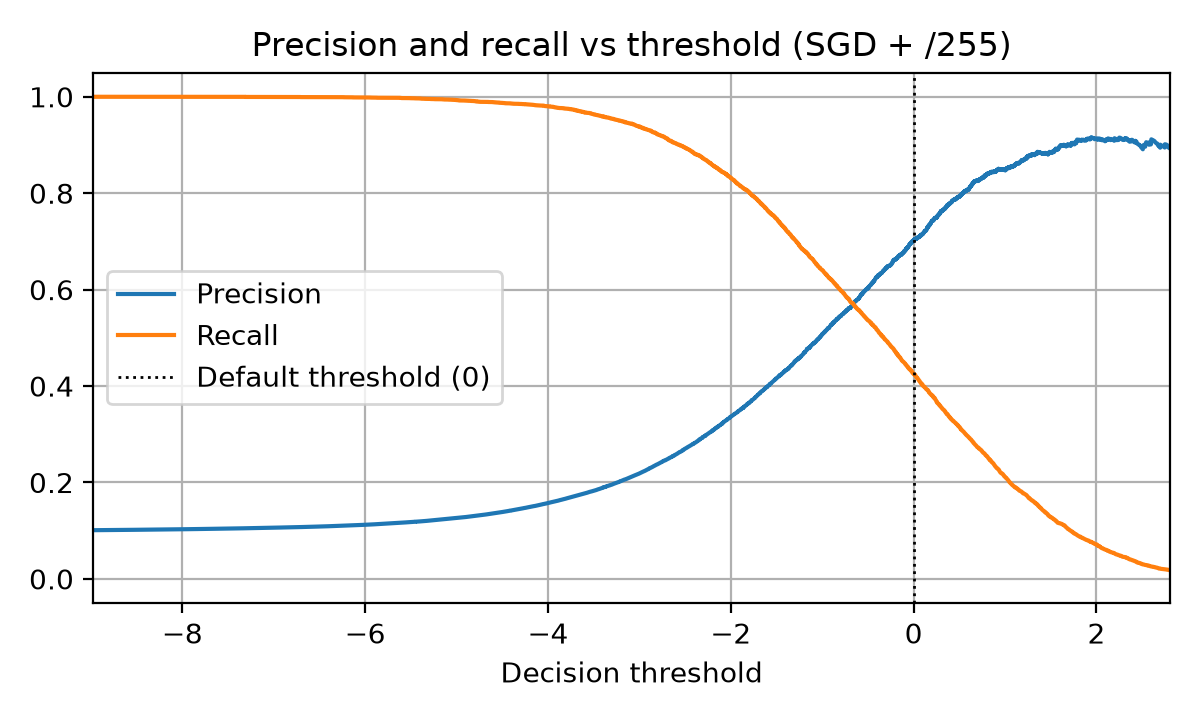

,policy,threshold,precision,recall,f1
0,precision >= 70%,-0.0147,0.7000,0.4282,0.5313
1,precision >= 80%,0.5373,0.8001,0.3068,0.4436
2,precision >= 90%,1.6427,0.9005,0.1117,0.1987
3,recall >= 60%,-0.8036,0.5451,0.6000,0.5712
4,recall >= 70%,-1.2850,0.4533,0.7000,0.5503
5,recall >= 80%,-1.7921,0.3663,0.8000,0.5025
6,max F1,-0.7796,0.5493,0.5955,0.5715


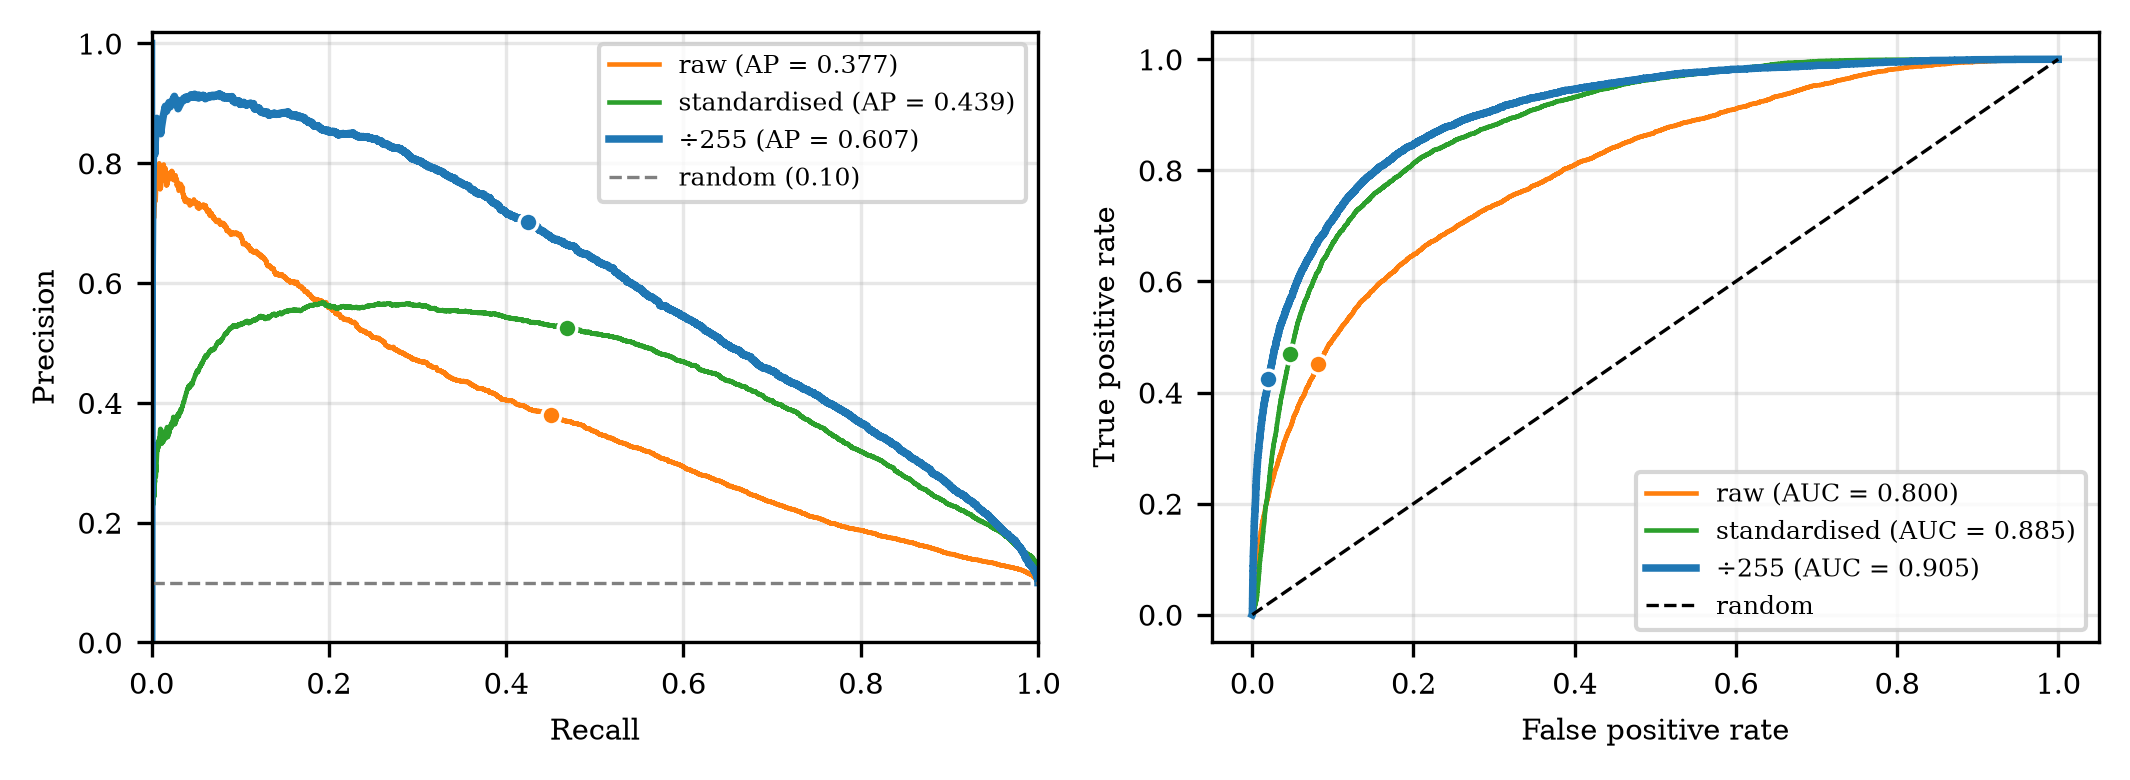

In [10]:
show("binary_precision_recall_vs_threshold_cv.png", 600)
display(bcv["policies"].round(4))
show("binary_pr_roc_cv.png", 950)

**Q9.1 Guiding questions**

1. **Precision as the threshold rises?** It climbs from about 0.10 (everything flagged) to about 0.91 at the top.
2. **Recall?** It falls from 1.0 to nearly 0.
3. **How could a company choose a threshold?** From its costs, with a policy such as the ones in the table above: a precision of at least 80% gives threshold 0.54 and recall 0.31;
   a recall of at least 70% gives threshold -1.29 and precision 0.45; the threshold that maximises F1 is -0.78 (precision 0.549, recall 0.596, F1 0.572, against F1 0.529 at the default).
4. **Why might the default threshold not be appropriate?** It is merely where the model's boundary happens to sit; it knows nothing about class imbalance or about the costs of errors.

**An important caveat, seen in section 14:** a numeric threshold chosen on cross-validated scores does *not* transfer to the model refitted on all the data (the scores shift), whereas ranking quality does.

## 10. ROC curve and ROC-AUC
The right panel of the figure above shows the ROC curves of the three variants, with the default threshold marked.

In [11]:
display(bcv["cv_table"][["ROC-AUC", "average precision"]].astype(float).round(4))

,ROC-AUC,average precision
"SGD, raw pixels",0.7996,0.3766
SGD + StandardScaler,0.8849,0.4386
SGD + /255,0.9050,0.6072
Dummy (always 'not shirt'),0.5000,0.1000


**Q10.1 Guiding questions**

1. **What does the ROC curve represent?** The trade-off between the true positive rate and the false positive rate as the threshold is varied.
2. **What are the axes?** x: false positive rate (the fraction of non-shirts wrongly flagged); y: true positive rate (recall).
3. **What does an AUC close to 1 mean?** The model ranks almost every shirt above almost every non-shirt.
4. **What does an AUC near 0.5 mean?** No better than random ranking (the diagonal).

*Values (cross-validation).* ROC-AUC 0.800 (raw), 0.885 (standardised), 0.905 (`/255`); average precision 0.377, 0.439, 0.607, against a random baseline of 0.10.
Because only 10% of the images are shirts, the ROC curve looks more favourable than the precision-recall curve: the false positive rate is divided by the many negatives.
Here the precision-recall view is the more informative one.

## 11. Multiclass classification: how it works
So far the answer was shirt / not shirt. Now all ten classes are predicted at once. The binary SGD classifier is extended automatically with the **one-vs-rest** strategy.
(This cell fits the models on the full training set, which takes a couple of minutes.)

In [12]:
mech = E.multiclass_mechanics(data)
print("True class of the first training image:", mech["true class of first image"])
for name in ("SGD, raw pixels", "SGD + /255"):
    print(f"\n=== {name}: coef_ shape {mech[name]['coef_ shape']}, predicted: {mech[name]['predicted']} ===")
    display(mech[name]["scores"])
print("\nOne-vs-one:", mech["one-vs-one"])

True class of the first training image: Pullover

=== SGD, raw pixels: coef_ shape (10, 784), predicted: Pullover ===


,class,decision score
0,Pullover,-2472.148
1,Coat,-4038.054
2,Shirt,-5852.766
3,Bag,-8451.783
4,T-shirt/top,-9211.105
5,Dress,-45441.341
6,Trouser,-48075.673
7,Sandal,-73401.715
8,Sneaker,-112301.011
9,Ankle boot,-225617.603



=== SGD + /255: coef_ shape (10, 784), predicted: Shirt ===


,class,decision score
0,Shirt,-2.360
1,Pullover,-2.638
2,Coat,-2.872
3,Bag,-3.139
4,T-shirt/top,-3.281
5,Trouser,-5.881
6,Dress,-7.078
7,Sneaker,-19.174
8,Sandal,-21.674
9,Ankle boot,-30.175



One-vs-one: {'binary classifiers': 45, 'predicted': 'Shirt'}


**Q11.1 Guiding questions**

1. **How many classes are predicted?** Ten.
2. **What does a decision score represent?** For each class, the signed distance of the image from that class's decision boundary: positive means "looks like this class rather than the rest".
   It is a confidence score, not a probability, and the ten scores are not forced to add up to one.
3. **Which class has the highest score?** For the first training image (a Pullover): the raw-pixel model scores Pullover highest (-2,472), so it is correct; the `/255` model scores Shirt highest (-2.36)
   just ahead of Pullover (-2.64), so it is wrong. All ten scores are negative for both models: no class "claims" the image, but the highest score still decides.
4. **Is a separate model trained for every class?** `fit` is called once, but `SGDClassifier` internally trains **ten one-vs-rest binary classifiers** (`coef_` has shape 10 x 784) and predicts the class with the highest score.
   The alternative, one-vs-one, trains a classifier for every pair of classes, 10 x 9 / 2 = **45** classifiers, and predicts by voting.

## 12. Evaluating the multiclass classifier
Four models with the same folds: the two linear models, k-nearest neighbours and a random forest (all default settings). Cross-validated out-of-fold predictions.
(Cross-validating four models takes a few minutes.)

In [13]:
mcv = E.multiclass_cv(data)
display(mcv["summary"])
print("Chosen by cross-validated accuracy:", mcv["best"])

,accuracy,macro-F1,Shirt F1,fold accuracies,CV time (s)
"SGD, raw pixels",0.80575,0.803333,0.508064,0.8038 / 0.8055 / 0.8079,82.0
SGD + /255,0.8319,0.82709,0.533459,0.8363 / 0.8281 / 0.8313,26.2
KNN (k=5),0.8516,0.850987,0.619222,0.8515 / 0.8513 / 0.8520,64.8
Random Forest,0.878917,0.877273,0.652206,0.8802 / 0.8785 / 0.8780,48.4
Dummy (always one class),0.1,0.018182,0.0,-,0.0


Chosen by cross-validated accuracy: Random Forest


Confusion matrix of the best model (percent of each true class):


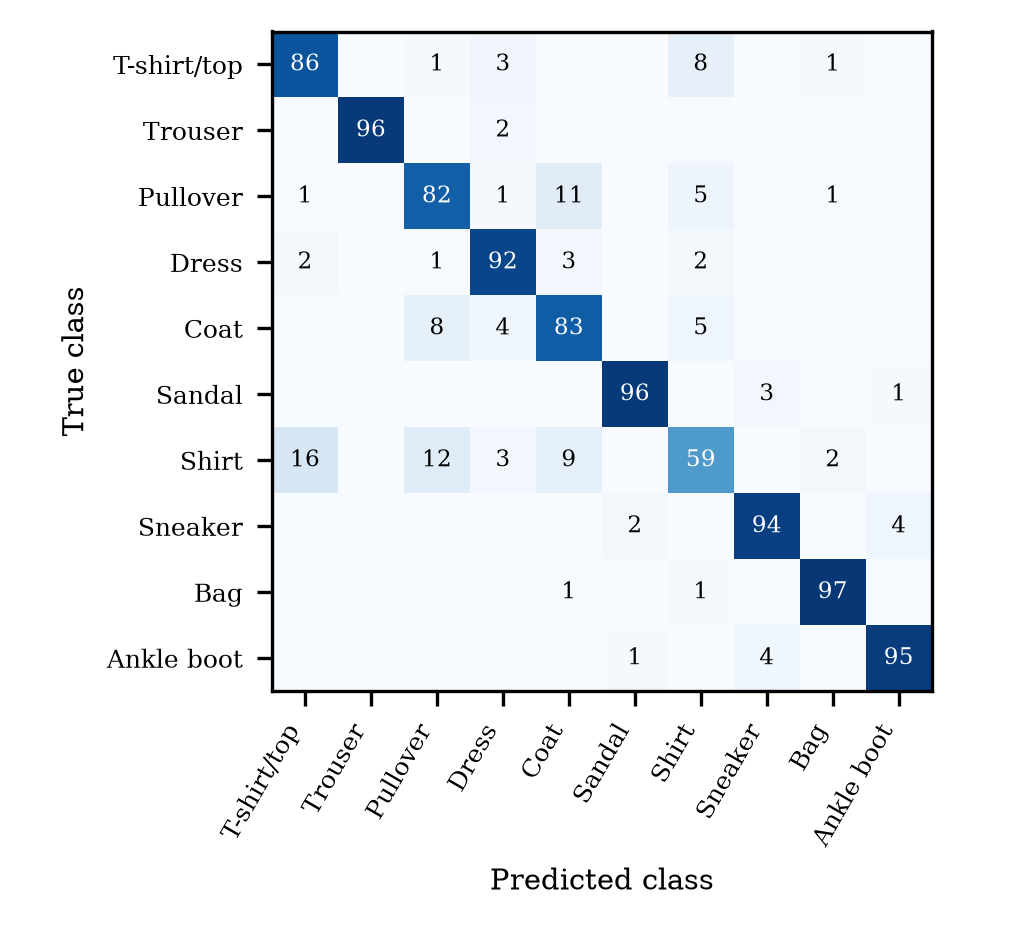

Most frequent confusions, SGD + /255:


,true class,predicted as,count,% of true class
0,Pullover,Coat,1183,19.7
1,Shirt,Coat,1119,18.6
2,Shirt,T-shirt/top,1082,18.0
3,Shirt,Pullover,716,11.9
4,Coat,Pullover,465,7.8
5,T-shirt/top,Dress,422,7.0
6,Shirt,Dress,373,6.2
7,Coat,Dress,308,5.1
8,T-shirt/top,Shirt,293,4.9
9,Sneaker,Sandal,291,4.8


Where do the true shirts go (SGD + /255)?


,% of images
Shirt,42.5
Coat,18.6
T-shirt/top,18.0
Pullover,11.9
Dress,6.2
Bag,2.2
Trouser,0.4
Sandal,0.0
Sneaker,0.0
Ankle boot,0.0


Per-class F1:


,"SGD, raw pixels",SGD + /255,KNN (k=5),Random Forest
T-shirt/top,0.7623,0.7964,0.8121,0.8398
Trouser,0.9573,0.9664,0.9772,0.9774
Pullover,0.7115,0.7235,0.7583,0.7983
Dress,0.8072,0.8348,0.8807,0.8940
Coat,0.6758,0.7190,0.7625,0.7982
Sandal,0.8865,0.9183,0.9015,0.9626
Shirt,0.5081,0.5335,0.6192,0.6522
Sneaker,0.8897,0.9113,0.9099,0.9370
Bag,0.9141,0.9353,0.9592,0.9636
Ankle boot,0.9207,0.9325,0.9292,0.9496


In [14]:
print("Confusion matrix of the best model (percent of each true class):")
show("multiclass_confusion_matrix_cv_best.png", 520)
print("Most frequent confusions, SGD + /255:")
display(mcv["top_confusions_sgd"])
print("Where do the true shirts go (SGD + /255)?")
display(mcv["shirt_destinations_sgd"].to_frame())
print("Per-class F1:")
display(mcv["per_class_f1"].round(4))

**Q12.1 Guiding questions**

1. **Which classes are confused most often?** Pullover and Coat, and Shirt with T-shirt/top, Pullover and Coat. For SGD + `/255`: Pullover -> Coat 19.7%, Shirt -> Coat 18.6%, Shirt -> T-shirt/top 18.0%,
   Shirt -> Pullover 11.9%, Coat -> Pullover 7.8%. Among the footwear, Sneaker -> Sandal is the main confusion (4.8%).
2. **Which are easiest?** Trouser (F1 0.966), Bag (0.935), Ankle boot (0.933), Sandal (0.918) and Sneaker (0.911).
3. **Why is a confusion matrix more informative than one accuracy number?** The overall accuracy (0.832) hides that errors are concentrated in a few class pairs. The matrix shows which classes fail and
   what they are mistaken for, which per-class precision and recall then quantify. Shirt is the weakest class (F1 0.534).

**Model comparison (cross-validated accuracy):** SGD raw 0.806, SGD + `/255` 0.832, KNN 0.852, random forest 0.879. The forest is chosen by cross-validation. It improves every class, but Shirt remains the hardest
(F1 0.652; only 58.6% of shirts are correct, the rest go to T-shirt/top 15.8%, Pullover 11.8% and Coat 9.4%). The confusion is therefore not removed by a nonlinear model.

## 13. Multilabel classification and its evaluation
In a multilabel problem an image can have several yes/no labels at once. We derive three labels from the class: **footwear** (Sandal, Sneaker, Ankle boot), **top** (T-shirt/top, Pullover, Coat, Shirt)
and **long-sleeved** (Pullover, Coat, Shirt). The classifier is k-nearest neighbours, which handles multilabel targets natively.

In [15]:
ls = E.label_summary(data)
display(ls["definitions"])
display(ls["labels active"])
print(E.multilabel_demo(data))

,label,classes,prevalence
0,footwear,"Sandal, Sneaker, Ankle boot",0.3
1,top,"T-shirt/top, Pullover, Coat, Shirt",0.4
2,long-sleeved,"Pullover, Coat, Shirt",0.3


,images,share
labels active per image,,
0,18000,0.3
1,24000,0.4
2,18000,0.3


{'true class': 'Pullover', 'true labels': {'footwear': np.int64(0), 'top': np.int64(1), 'long-sleeved': np.int64(1)}, 'predicted labels': {'footwear': np.int64(0), 'top': np.int64(1), 'long-sleeved': np.int64(1)}}


**Q13.1 Guiding questions (the problem)**

1. **How does this differ from ordinary multiclass classification?** Multiclass assigns exactly one of K mutually exclusive classes; multilabel asks several independent yes/no questions, so an image can have none, one or several labels.
2. **How many labels can an observation receive?** Between 0 and 3 of the three; in this dataset at most two are active at once (Trouser, Dress and Bag have none, 30% of the images; T-shirt/top and the footwear have one; Pullover, Coat and Shirt have two).
3. **What does a prediction for one image represent?** A vector of three yes/no values: for the first image (a Pullover) `[footwear 0, top 1, long-sleeved 1]`, which is correct.

In [16]:
mlcv = E.multilabel_cv(data, mcv)
display(mlcv["scores"].round(4))
print("KNN macro-F1 per fold:", [round(v, 4) for v in mlcv["fold_macro_f1"]])
display(mlcv["per_label"])
print("Exact-match rate by original class (lowest first):")
display(mlcv["exact_by_class"].to_frame())
print("Two routes to the same target (cross-validation):")
display(mlcv["route_comparison"].round(4))

,macro-F1,micro-F1,weighted-F1,samples-F1,exact-match accuracy,Hamming loss
KNN (k=5),0.9584,0.9589,0.9589,0.9586,0.938,0.0276
Baseline: all labels = yes,0.4982,0.5000,0.5055,0.4400,0.000,0.6667


KNN macro-F1 per fold: [0.959, 0.9579, 0.9581]


,precision,recall,f1-score,support
footwear,0.9972,0.9959,0.9966,18000.0
top,0.9482,0.9790,0.9634,24000.0
long-sleeved,0.9137,0.9166,0.9152,18000.0
micro avg,0.9524,0.9654,0.9589,60000.0
macro avg,0.9530,0.9639,0.9584,60000.0
weighted avg,0.9525,0.9654,0.9589,60000.0


Exact-match rate by original class (lowest first):


,exactly right
Shirt,0.8052
T-shirt/top,0.8570
Dress,0.8572
Bag,0.9480
Coat,0.9645
Pullover,0.9802
Trouser,0.9802
Sandal,0.9898
Ankle boot,0.9983
Sneaker,0.9997


Two routes to the same target (cross-validation):


,macro-F1,micro-F1,weighted-F1,samples-F1,exact-match accuracy,Hamming loss
KNN multilabel (direct),0.9584,0.9589,0.9589,0.9586,0.9380,0.0276
"SGD multiclass /255, mapped to labels",0.9467,0.9472,0.9468,0.9452,0.9259,0.0346


**Q13.2 Guiding questions (the evaluation)**

1. **Why is evaluating a multilabel classifier different from a binary one?** There is not one positive class but several labels, so one score per label must be *combined*; and a prediction can be partly right
   (two labels correct, one wrong), which a single accuracy cannot express.
2. **Results.** Macro-F1 0.958 (F1 per label: footwear 0.997, top 0.963, long-sleeved 0.915), exact-match accuracy 0.938, Hamming loss 0.028; the all-"yes" baseline scores macro-F1 0.498 and exact match 0.
   The scores are far higher than in the ten-class task because Pullover, Coat and Shirt carry identical labels, so confusing them no longer counts as an error; the remaining errors concern Shirt, T-shirt/top and Dress.
   Mapping the ten-class SGD predictions to the labels gives macro-F1 0.947 against 0.958 for KNN trained directly.
3. **Why choose the metric according to the problem?** Macro-F1 gives every label equal weight (it exposes the hard label), micro-F1 pools all decisions (dominated by frequent labels), weighted-F1 weights by label frequency,
   samples-F1 averages per image, and exact match demands the whole label set to be right. The right one depends on what the application needs.

## 14. Final evaluation on the held-out test set
Everything above was decided by cross-validation on the training set. Now each model is fitted once on all training images and evaluated once on the 10,000 test images.
The binary threshold (max-F1 in cross-validation) and the multiclass model (best cross-validated accuracy) were fixed beforehand.

,threshold,accuracy,precision,recall,f1,TP,FP,FN,TN,ROC-AUC,average precision
"SGD, raw pixels @ threshold 0",0.0000,0.8712,0.4219,0.778,0.5471,778.0,1066.0,222.0,7934.0,0.9095,0.5335
SGD + StandardScaler @ threshold 0,0.0000,0.9106,0.5643,0.465,0.5099,465.0,359.0,535.0,8641.0,0.8855,0.4633
SGD + /255 @ threshold 0,0.0000,0.9188,0.5957,0.585,0.5903,585.0,397.0,415.0,8603.0,0.9126,0.6324
SGD + /255 @ threshold -0.780 (max F1 in CV),-0.7796,0.8744,0.4293,0.777,0.5530,777.0,1033.0,223.0,7967.0,0.9126,0.6324
Dummy (always 'not shirt'),NaN,0.9000,0.0000,0.000,0.0000,0.0,0.0,1000.0,9000.0,0.5000,0.1000


Fraction of images flagged as shirts, cross-validation vs test:


,cross-validation,test
threshold 0,0.0605,0.0982
max-F1 threshold,0.1084,0.1810


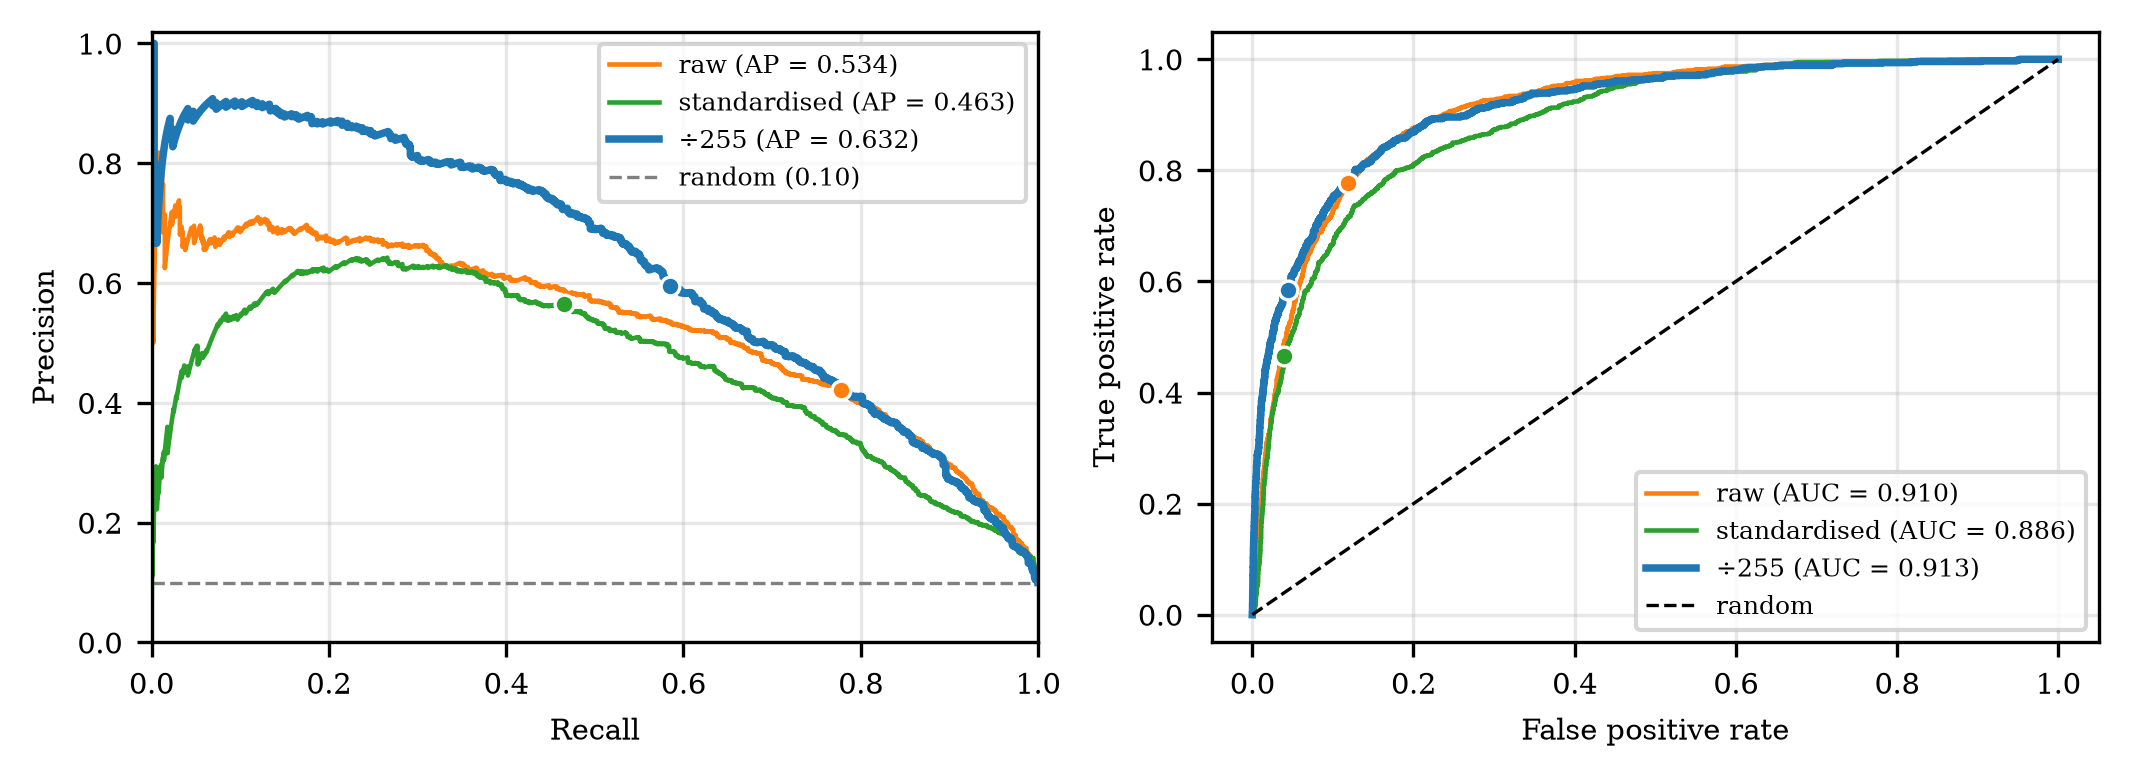

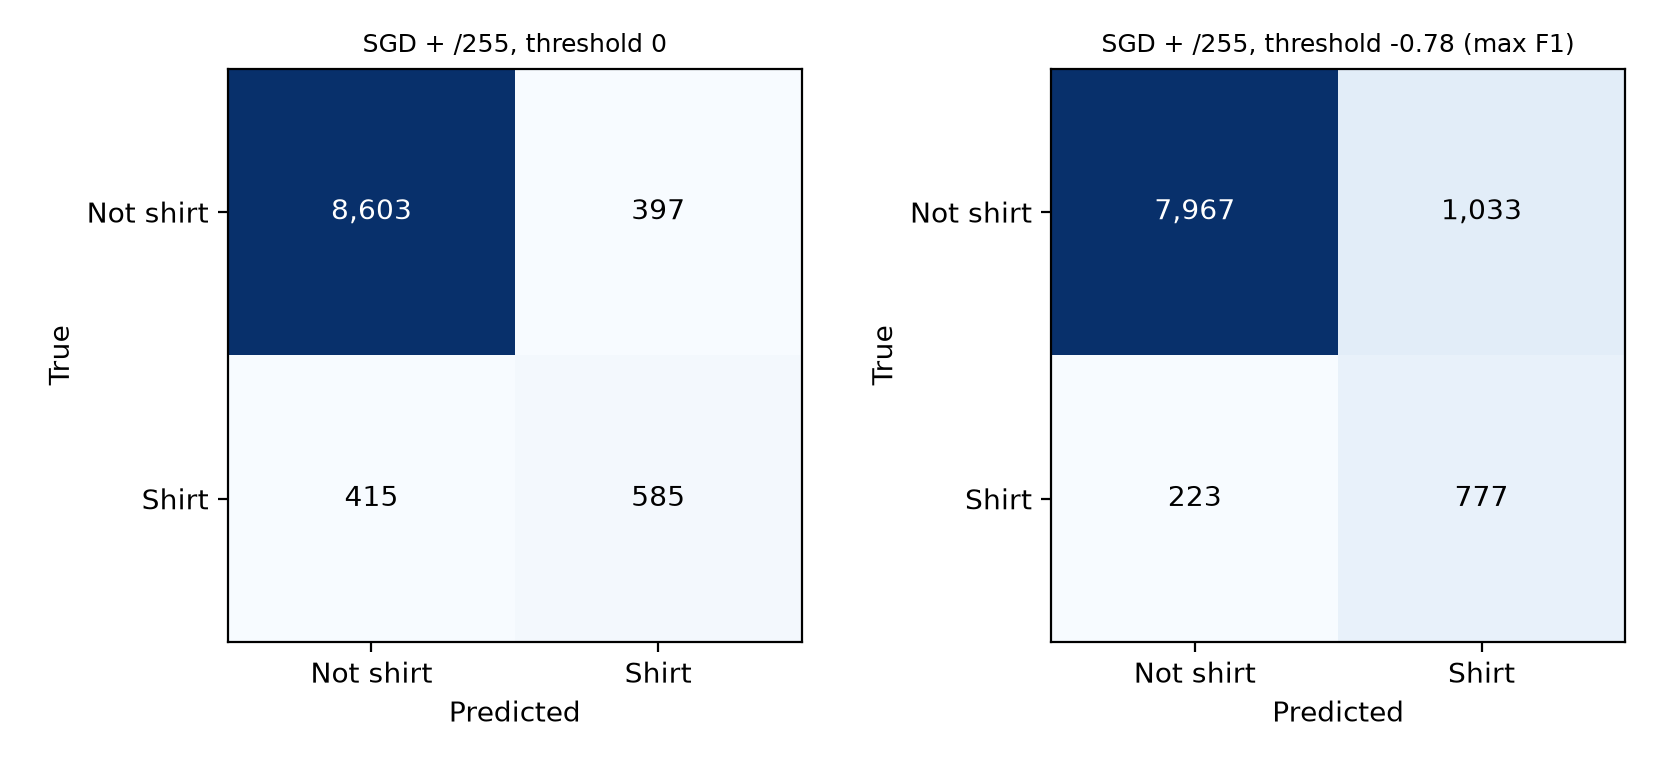

In [17]:
btest = E.binary_test(data, bcv)
display(btest["table"].drop(columns=["% flagged"]).round(4))
print("Fraction of images flagged as shirts, cross-validation vs test:")
display(pd.DataFrame({"cross-validation": bcv["flagged_cv"], "test": btest["flagged_test"]}).round(4))
show("fig_pr_roc.png", 950)
show("final_binary_confusion_matrices_test.png", 700)

,test accuracy,95% CI (+/-),test macro-F1,test Shirt F1,CV accuracy,fit time (s),predict time (s)
"SGD, raw pixels",0.8085,0.0077,0.7939,0.3370,0.8058,41.4,0.0
SGD + /255,0.8448,0.0071,0.8429,0.6022,0.8319,12.6,0.0
KNN (k=5),0.8589,0.0068,0.8580,0.6286,0.8516,0.0,15.0
Random Forest,0.8847,0.0063,0.8830,0.6733,0.8789,23.1,0.2


,"SGD, raw pixels",SGD + /255,KNN (k=5),Random Forest
T-shirt/top,0.7570,0.8099,0.8164,0.8380
Trouser,0.9463,0.9672,0.9752,0.9798
Pullover,0.7253,0.7601,0.7795,0.8004
Dress,0.8144,0.8708,0.8973,0.9128
Coat,0.7321,0.7528,0.7931,0.8296
Sandal,0.8928,0.9153,0.8967,0.9614
Shirt,0.3370,0.6022,0.6286,0.6733
Sneaker,0.8856,0.8897,0.9069,0.9286
Bag,0.9335,0.9431,0.9651,0.9620
Ankle boot,0.9146,0.9175,0.9216,0.9443


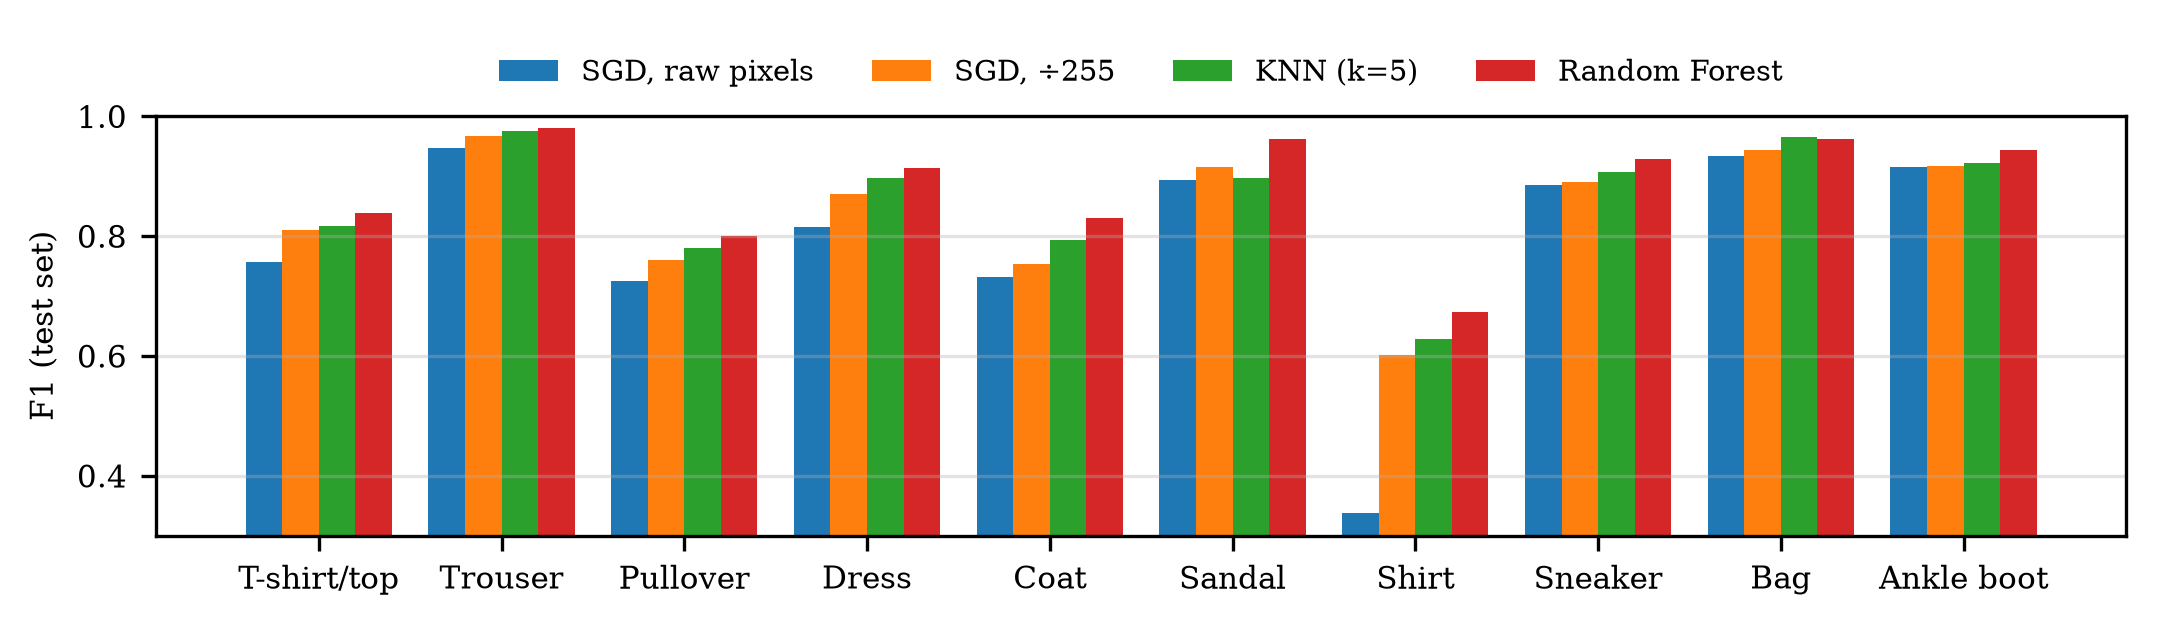

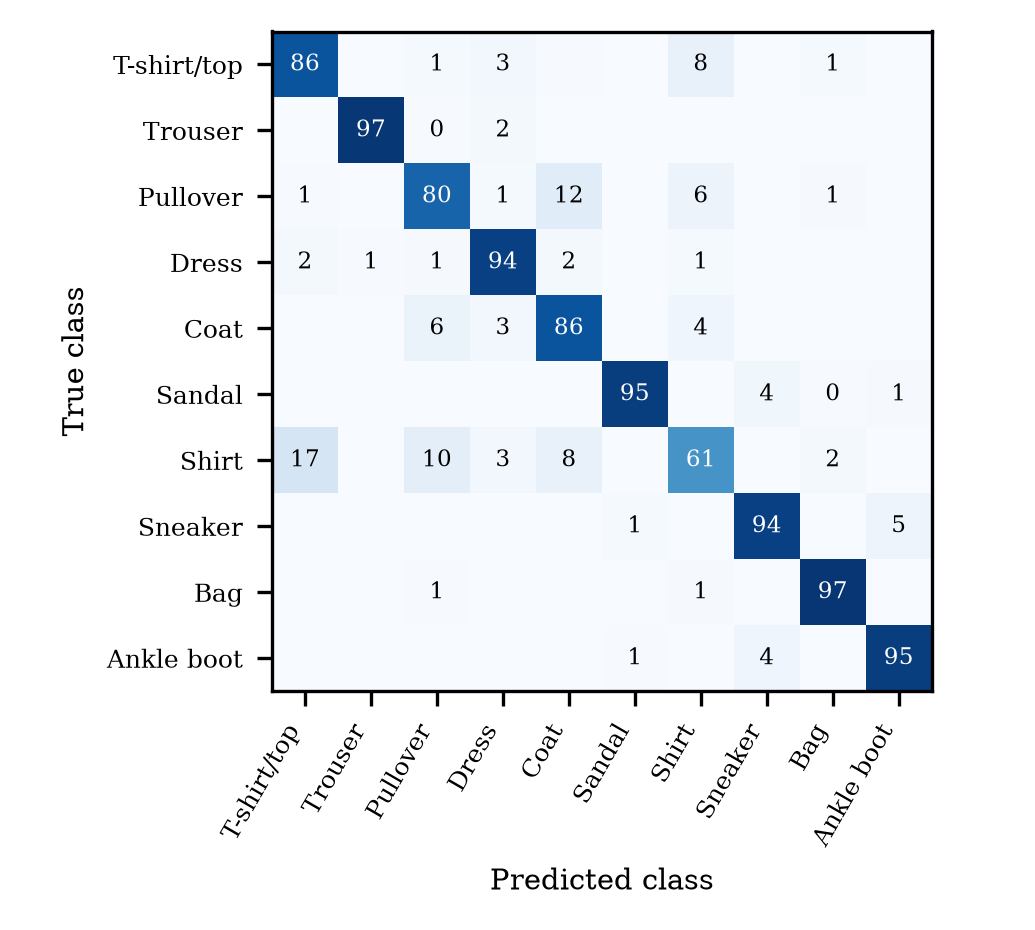

Where do the true shirts go on the test set? Random Forest


,% of images
Shirt,61.1
T-shirt/top,16.6
Pullover,10.0
Coat,7.5
Dress,2.8
Bag,1.9
Trouser,0.1
Sandal,0.0
Sneaker,0.0
Ankle boot,0.0


In [18]:
mtest = E.multiclass_test(data, mcv)
display(mtest["table"].round(4))
display(mtest["per_class_f1"].round(4))
show("fig_per_class_f1.png", 950)
show("fig_confusion_best_model.png", 520)
print("Where do the true shirts go on the test set?", mtest["best"])
display(mtest["shirt_destinations"].to_frame())

In [19]:
mltest = E.multilabel_test(data)
display(mltest["scores"].round(4))
display(mltest["per_label"])
key = E.key_results(bcv, btest, mcv, mtest, mlcv, mltest)
key

,macro-F1,micro-F1,weighted-F1,samples-F1,exact-match accuracy,Hamming loss
KNN (k=5),0.9591,0.96,0.9600,0.9616,0.9401,0.0268
Baseline: all labels = yes,0.4982,0.50,0.5055,0.4400,0.0000,0.6667


,precision,recall,f1-score,support
footwear,0.9963,0.9953,0.9958,3000.0
top,0.9550,0.9808,0.9677,4000.0
long-sleeved,0.9154,0.9123,0.9139,3000.0
micro avg,0.9555,0.9646,0.9600,10000.0
macro avg,0.9556,0.9628,0.9591,10000.0
weighted avg,0.9555,0.9646,0.9600,10000.0


{'binary_cv_main': {'accuracy': 0.9244666666666667,
  'precision': 0.7022038567493113,
  'recall': 0.42483333333333334,
  'f1': 0.5293873312564902,
  'ROC-AUC': 0.9049885617283951,
  'average precision': 0.6072346881703506},
 'binary_test_main': {'accuracy': 0.9188,
  'precision': 0.5957230142566191,
  'recall': 0.585,
  'f1': 0.5903128153380425,
  'ROC-AUC': 0.9126496666666667,
  'average precision': 0.6324386701827893},
 'binary_cv_threshold_max_f1': -0.7795963832272297,
 'binary_flagged_fraction': {'cv': {'threshold 0': 0.0605,
   'max-F1 threshold': 0.10841666666666666},
  'test': {'threshold 0': 0.0982, 'max-F1 threshold': 0.181}},
 'multiclass_cv_accuracy': {'SGD, raw pixels': 0.80575,
  'SGD + /255': 0.8319,
  'KNN (k=5)': 0.8516,
  'Random Forest': 0.8789166666666667},
 'multiclass_test_accuracy': {'SGD, raw pixels': 0.8085,
  'SGD + /255': 0.8448,
  'KNN (k=5)': 0.8589,
  'Random Forest': 0.8847},
 'multiclass_best_by_cv': 'Random Forest',
 'multilabel_cv_macro_f1': 0.95836081

**Reading the test results**

* **Multiclass:** the test ranking confirms cross-validation: raw SGD 0.809 < SGD + `/255` 0.845 < KNN 0.859 < random forest 0.885 (95% intervals about +/-0.007). Test accuracy is 0.3-1.3 points above the
  cross-validated accuracy, consistent with training on 60,000 instead of 40,000 images. The forest trains in 36 s, SGD + `/255` in 22 s; KNN needs no training but 26 s to predict 10,000 images.
  Shirt remains the weakest class (forest F1 0.673; 61% of test shirts correct).
* **Binary:** SGD + `/255` at the default threshold: precision 0.596, recall 0.585, F1 0.590, ROC-AUC 0.913, average precision 0.632 (cross-validation: 0.702 / 0.425 / 0.529 / 0.905 / 0.607).
  The cross-validated max-F1 threshold (-0.78) did **not** transfer: on the test set it gives recall 0.777 but precision 0.429 and F1 0.553, below the default (0.590). The final model's scores are shifted relative to the fold models
  (it flags 18.1% of test images at that threshold against about 10.8% in cross-validation), because hinge-loss scores are not calibrated. Ranking quality transfers, an absolute cutoff does not.
* **Unstable raw-pixel SGD:** its pooled cross-validated ROC-AUC (0.80) was far below its test value (0.91), and its Shirt F1 collapsed from 0.508 (cross-validation) to 0.337 (test): out-of-fold scores come from three different models whose offsets differ.
* **Multilabel:** KNN macro-F1 0.959 and exact match 0.940 on the test set (cross-validation 0.958 and 0.938).

## 15. Conclusions

1. **Accuracy alone is misleading** when the positive class is rare; precision, recall, F1 and the precision-recall curve describe the behaviour of the classifier.
2. **The difficulty is concentrated** in a cluster of look-alike upper-body garments (Shirt, T-shirt/top, Pullover, Coat), whichever model is used.
3. **Preprocessing matters:** dividing pixels by 255 clearly outperformed both raw pixels and per-pixel standardisation.
4. **Nonlinear models help:** about four points of accuracy over the linear baseline (random forest 0.885 against SGD + `/255` 0.845 on the test set), at a modest cost.
5. **Evaluation pitfalls:** pooled cross-validated scores of an unstable model, and numeric thresholds chosen on them, do not carry over to a model refitted on all the data.
6. **Multilabel** is easy by construction, because the labels merge the confusable classes.

*Limitations:* default hyper-parameters (no tuning); raw pixels, no convolutional features; a single run of 3-fold cross-validation; labels derived from the classes; uncalibrated scores; one dataset at 28 x 28 resolution.
*Future work:* convolutional networks, probability calibration or a separate validation set for threshold selection, hyper-parameter tuning, repeated cross-validation.